# AICE Professional 주피터라이트 실전 모의고사 03회 — 군 PBL 합성데이터(질의 응답시간 · 정비 보고 · 열상 표적)

## [ 필독 ] AICE Professional 모의고사 유의사항

- 공식 샘플문항(가공식품 카테고리 분류)과 **같은 시험지 형식**으로 만든 모의고사입니다. 3문항, 180분 기준입니다.
- 공식 시험과 같은 **Tabular / Text / Image 3유형**입니다. 2번 Text 문항은 공식 샘플(상품명 → 카테고리)과 같은 텍스트 분류입니다.
- 본인 스스로 모델을 만들고 **달성 목표 이상의 성능**이 나오도록 개발해야 합니다. 정답(테스트 라벨)은 제공되지 않습니다.
  대신 이 노트북 **맨 마지막 셀**(전체 자동 채점, 정답 키 인코딩)로 제출 파일을 스스로 채점할 수 있습니다(연습용).

## 사용할 수 있는 라이브러리 (주피터라이트 판)

이 모의고사는 **브라우저 주피터라이트(Pyodide · Python 3.14)** 에서 설치 없이 끝까지 풀 수 있도록 라이브러리를 제한했습니다.
필요한 라이브러리는 주피터라이트에 **미리 설치**되어 있습니다. 맨 위 '브라우저 실습' 셀은 확인만 하고 바로 끝납니다(Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다).

| 구분 | 쓸 수 있음 | 쓰지 않음(브라우저에서 안 됨) |
|---|---|---|
| 데이터·그림 | numpy · pandas · matplotlib · seaborn · Pillow | — |
| 머신러닝 | scikit-learn · LightGBM · XGBoost · imbalanced-learn · joblib | CatBoost |
| 텍스트 | scikit-learn 의 CountVectorizer · TfidfVectorizer · 내장 영어 불용어, **NLTK**(불용어·토큰화·어간 추출, 데이터는 `/drive/nltk_data` 에 미리 들어 있음) | 형태소 분석기 · BERT 등 사전학습 언어 모델 |
| 딥러닝 | `tensorflow.keras` 문법(TensorFlow.js 로 실행되는 대체 구현체, 미리 설치): `Sequential`·함수형(`Input` → 층 → `Model`) · Dense · Dropout · BatchNormalization · Conv2D · MaxPooling2D · GlobalAveragePooling2D · Embedding · LSTM · GRU · 콜백 3종(EarlyStopping · ModelCheckpoint · ReduceLROnPlateau) · `load_img` · `img_to_array` · `image_dataset_from_directory` · `ImageDataGenerator` · `model.save` / `load_model` · **MobileNet v1 전이학습**(`alpha=0.25`, 224×224, `weights='imagenet'` 만) | PyTorch · 다른 사전학습 모델(MobileNetV2/V3 · ResNet · EfficientNet 등) · 사용자 정의 층·손실 · GPU |

- 이미지는 64×64 정도로 줄여 작은 CNN 을 직접 학습하거나, MobileNet v1(alpha 0.25)로 특징을 뽑아 분류기를 학습하세요(전이학습). 브라우저 TensorFlow.js 는 CPython TensorFlow 와 수치가 조금 달라 딥러닝 점수가 약간 다르게 나올 수 있습니다.
- 학습이 오래 걸리면 epoch 를 줄이거나 조기 종료(EarlyStopping)를 쓰세요. 최신 Chrome·Edge 를 권장합니다.

## 시간 배분(180분)

| 문항 | 권장 시간 | 먼저 할 일 |
|---|---|---|
| 1. Tabular (30점) | 50분 | `info()`·`describe()` 로 자료형·결측 확인 → 기본 모델로 제출 파일부터 만들기 |
| 2. Text (35점) | 60분 | 라벨 분포·문장 길이 확인 → TF-IDF + 선형 모델로 기준 점수 |
| 3. Image (35점) | 60분 | 압축 풀기·폴더 구조 확인 → 작은 CNN 으로 기준 점수 |
| 마무리 | 10분 | 제출 파일 6개 이름·열 구조 확인 → 맨 마지막 채점 셀 실행 |

## 시험 자원 가이드

| 구분 | 공식 시험 | 이 모의고사 |
|---|---|---|
| IDE | CPU 8 core · Memory 32G · GPU 1개(VRAM 16GB) | **브라우저 주피터라이트**(설치 없음, CPU) — Colab·로컬 Jupyter 에서도 그대로 실행됨 |
| SW | Python 3.10 · TensorFlow 2.13 · PyTorch 2.1 | Python 3.14(Pyodide) · scikit-learn · LightGBM · XGBoost · Keras 문법(TensorFlow.js) — 위 표의 라이브러리만 |

## 유의 사항

- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 제출 파일명은 **고정**입니다: `answer_1~3` 모델 파일과 `answer_1~3.csv`.


문제에 제시되는 가이드는 필수적으로 준수하여 주시기 바랍니다. 이를 준수하지 않을 경우 채점 제한 또는 0점 처리될 수 있으니
각별히 유의해 주시기 바랍니다.

#### **[학습 정보]**
- 학습 목표 : Tabular · Text · Image 예측 모델 3종을 만들어 달성 목표 이상의 예측 파일을 제출하고, 제출한 코드로 같은 모델이 재현되게 할 수 있다
- AICE 역량 : PT1·PT2 표 데이터 / PX1·PX2 텍스트 / PI1·PI2 이미지 / PS1 제출 파일 형식·재현성
- 제출 파일 : `answer_1~3` 모델 파일(.pkl · .h5 등)과 `answer_1~3.csv` — **파일명은 고정**입니다(이름을 바꾸면 채점되지 않음)

| 문항 | 문제 | 달성 목표 | 역량 | 기술 | 예상 시간 |
|---|---|---|---|---|---|
| 1. Tabular | 군수 데이터 질의 응답시간 예측 | RMSE 0.925 이하 | PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | pandas, scikit-learn(Ridge, RandomForestRegressor, GradientBoostingRegressor, KFold), joblib | 50분 |
| 2. Text | 정비 보고 문장 고장 계통 분류 | 정확도 0.91 이상 | PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | pandas, scikit-learn(CountVectorizer, TfidfVectorizer, MultinomialNB, LinearSVC), joblib | 60분 |
| 3. Image | 열상 영상 표적 분류 | 정확도 0.93 이상 | PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | pandas, Keras(TensorFlow.js) | 60분 |

In [35]:
# (브라우저 실습) 주피터라이트에는 tensorflow(TensorFlow.js 대체 구현체)·scikit-learn·LightGBM 등이 미리 설치되어 있어 이 셀은 확인만 합니다.
# Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다.
import os, sys, importlib.util
if 'pyodide' in sys.modules:
    os.environ['AICE_IMG_DIR'] = '/tmp/aice_images/' + os.path.basename(os.getcwd())   # 이미지 압축은 메모리 폴더에 풂(빠름)
    if not ('tensorflow' in sys.modules or importlib.util.find_spec('tensorflow')):
        # 미리 설치되지 않은 사이트(패치 전 주피터라이트)에서만: 같은 폴더의 tfjs_keras.py 를 불러옵니다
        sys.path[:0] = [os.getcwd(), '/drive']
        import tfjs_keras
        await tfjs_keras.load()
print('준비 완료 — 다음 셀로 넘어가세요.')

준비 완료 — 다음 셀로 넘어가세요.


## 1. Tabular 문제 - 군수 데이터 질의 응답시간 예측 (30점)

<sub>학습 목표: 군수 데이터 질의 응답시간 예측 모델로 테스트 RMSE 0.925 이하을 달성할 수 있다 | 역량: PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | 기술: pandas, scikit-learn(Ridge, RandomForestRegressor, GradientBoostingRegressor, KFold), joblib | 난이도: 실전 | 예상 시간: 50분</sub>

### 문제 개요

군수 데이터 질의응답 시스템의 질의 기록(부대·질의 유형·응답 정확도·재질의 여부·사용자 만족도·질의 내용)으로 그 질의의 **응답 시간(초)** 을 예측하는 회귀 문제입니다. 데이터가 450건으로 작아 교차검증으로 모델을 고르는 연습을 합니다.

제공된 훈련 데이터셋을 활용해 회귀 모델을 개발하고, 테스트 데이터셋의 '응답시간초' 값을 예측하시기 바랍니다.

### 달성 목표

"01_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **RMSE 0.925 이하**를 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `01_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `01_test_x.csv`: 테스트 데이터셋입니다. 라벨('응답시간초') 값이 제외되어 있습니다.

**Label 정보**

- '응답시간초' : 응답까지 걸린 시간(초, 0.5~12.8)

**Data 정보**

- 'id' : 질의번호
- '부대코드' : 부대
- '질의유형' : 재산현황·소요판단·현황비교 등
- '응답정확도' : 응답 정확도 점수
- '재질의여부' : 다시 질의했는지(여/부)
- '사용자만족도' : 1~9
- '질의내용' : 질의 문장(4종)

**데이터 출처** — 제7회 데이터한마당 본선 18팀 군수 데이터 질의응답 **합성데이터** 450건 — 실제 부대 자료 아님

### 데이터 예시

`01_train.csv`

| id | 부대코드 | 질의유형 | 응답정확도 | 재질의여부 | 사용자만족도 | 질의내용 | 응답시간초 |
|---|---|---|---|---|---|---|---|
| LENS-00110 | 부대C | 현황비교 | 67 | 부 | 1 | 탄약 소요 판단해줘 | 6.9 |
| LENS-00331 | 부대C | 현황비교 | 93.2 | 부 | 4 | 탄약 소요 판단해줘 | 4.4 |
| LENS-00326 | 부대C | 가동률 | 109 | 부 | 6 | 이번달 장비가동률은 | 2.7 |

`01_test_x.csv`

| id | 부대코드 | 질의유형 | 응답정확도 | 재질의여부 | 사용자만족도 | 질의내용 |
|---|---|---|---|---|---|---|
| LENS-00062 | 부대B | 소요판단 | 85.3 | 여 | 3 | 탄약 소요 판단해줘 |
| LENS-00052 | 부대C | 소요판단 | 71 | 부 | 1 | 인접부대와 현황 비교해줘 |
| LENS-00337 | 부대A | 소요판단 | 69.4 | 부 | 1 | 상급부대 재산현황을 알려줘 |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 군수 데이터 질의 응답시간 예측 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_1.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('응답시간초') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_1.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '응답시간초' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '응답시간초' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 데이터가 작으므로 학습·검증을 한 번만 나누면 점수가 흔들립니다. **K-Fold 교차검증** 으로 모델을 비교하세요.
- 범주형(부대코드·질의유형·질의내용·재질의여부)은 원-핫 인코딩합니다.
- 평가 지표는 **RMSE**(낮을수록 좋음)입니다. 예측값은 초 단위 실수로 제출하세요.

### 채점 진행 방식 안내

- 1번 문항 배점 : 30점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_1.csv 로 제출된 예측 데이터를 정답지와 대조하여, **RMSE 1.0175 이하** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [36]:

import pandas as pd
import joblib

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

# 1. 데이터 불러오기
train = pd.read_csv('/content/01_train.csv')
test = pd.read_csv('/content/01_test_x.csv')

train.info(verbose=False)
LABEL = '응답시간초'

# 2. 학습 데이터와 정답 분리
X = train.drop(columns=['id', LABEL])
y = train[LABEL]
X_test = test.drop(columns=['id'])

# 3. 범주형 데이터 원-핫 인코딩
X = pd.get_dummies(X)
X_test = pd.get_dummies(X_test)

# 4. 학습 데이터와 테스트 데이터 컬럼 맞추기
X, X_test = X.align(X_test, join='outer', axis=1, fill_value=0)

# 5. K-Fold 교차검증
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    'GradientBoosting': GradientBoostingRegressor(
        random_state=42
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model, X, y,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )
    print(f'{name} RMSE: {-scores.mean():.4f}')

# 6. Ridge alpha 값 비교
for alpha in [1, 10, 20, 50, 100]:
    model = Ridge(alpha=alpha)

    scores = cross_val_score(
        model, X, y,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )
    print(f'alpha={alpha} RMSE: {-scores.mean():.4f}')

# 7. 최적 모델 전체 학습
best_model = Ridge(alpha=50)
best_model.fit(X, y)

# 8. 모델 파일 저장
joblib.dump(best_model, '/content/answer_1.pkl')

# 9. 테스트 데이터 예측
pred = best_model.predict(X_test)

# 10. 예측 CSV 저장
answer = test.copy()
answer[LABEL] = pred
answer.to_csv('/content/answer_1.csv', index=False)

# 11. 최종 결과 확인
print('예측 결과 크기:', answer.shape)
print(answer.head())
print('answer_1.pkl 및 answer_1.csv 저장 완료!')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337 entries, 0 to 336
Columns: 8 entries, id to 응답시간초
dtypes: float64(2), int64(1), object(5)
memory usage: 21.2+ KB
Ridge RMSE: 0.9302
RandomForest RMSE: 1.0205
GradientBoosting RMSE: 1.0092
alpha=1 RMSE: 0.9302
alpha=10 RMSE: 0.9258
alpha=20 RMSE: 0.9231
alpha=50 RMSE: 0.9205
alpha=100 RMSE: 0.9219
예측 결과 크기: (113, 8)
           id 부대코드  질의유형  응답정확도 재질의여부  사용자만족도            질의내용     응답시간초
0  LENS-00062  부대B  소요판단   85.3     여       3      탄약 소요 판단해줘  5.173419
1  LENS-00052  부대C  소요판단   71.0     부       1   인접부대와 현황 비교해줘  6.747607
2  LENS-00337  부대A  소요판단   69.4     부       1  상급부대 재산현황을 알려줘  6.938268
3  LENS-00141  부대A  재산현황   93.4     부       3      이번달 장비가동률은  4.185552
4  LENS-00317  부대C  재산현황   95.5     부       2      이번달 장비가동률은  4.446170
answer_1.pkl 및 answer_1.csv 저장 완료!


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

자료형·결측·정답 분포를 확인합니다. 번호·날짜 원문·누수 열은 빼고 범주형은 원-핫 인코딩합니다. '참고'의 파생 변수를 만든 뒤 선형 모델과 트리 모델(LightGBM 등)을 **교차검증 RMSE** 로 비교해 더 나은 쪽으로 전체 학습하세요.

- 이 문항의 핵심: 데이터가 작으므로 학습·검증을 한 번만 나누면 점수가 흔들립니다. **K-Fold 교차검증** 으로 모델을 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pandas`, `joblib`, `Ridge`, `RandomForestRegressor`, `GradientBoostingRegressor`, `KFold`, `cross_val_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.linear_model import ____
from sklearn.ensemble import ____, ____
from sklearn.model_selection import ____, ____

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')
train.info(verbose=False)
LABEL = '____'


# ▷ 후보 모델을 교차검증으로 비교(점수 출력)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_1.pkl`(모델) · `answer_1.csv`(예측)

</details>

## 2. Text 문제 - 정비 보고 문장 고장 계통 분류 (35점)

<sub>학습 목표: 정비 보고 문장 고장 계통 분류 모델로 테스트 정확도 0.91 이상을 달성할 수 있다 | 역량: PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | 기술: pandas, scikit-learn(CountVectorizer, TfidfVectorizer, MultinomialNB, LinearSVC), joblib | 난이도: 중급 | 예상 시간: 60분</sub>

### 문제 개요

장비 **정비 보고 문장**(장비명·증상·주행거리·조치)으로 고장이 난 **계통 6종**(엔진·동력전달·제동·전기·유압·현가/궤도)을 분류하는 문제입니다. '소음'·'누유'·'경고등' 처럼 여러 계통에 같이 나오는 단어와, 다른 계통을 '이상 없음' 으로 언급한 문구가 섞여 있습니다.

제공된 훈련 데이터셋을 활용해 텍스트 다중 분류(6종) 모델을 개발하고, 테스트 데이터셋의 '고장계통' 값을 예측하시기 바랍니다.

### 달성 목표

"02_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 91% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `02_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `02_test_x.csv`: 테스트 데이터셋입니다. 라벨('고장계통') 값이 제외되어 있습니다.

**Label 정보**

- '고장계통' : 엔진 / 동력전달 / 제동 / 전기 / 유압 / 현가·궤도

**Data 정보**

- 'id' : 테스트 행 번호(테스트에만)
- '정비보고' : 정비 보고 문장

**데이터 출처** — v3 합성 — 전차·자주포·장갑차·전술차량 정비 보고 문장 3,600건(본선 12·20팀 정비 업무 형식, 실제 기록 아님)

### 데이터 예시

`02_train.csv`

| 정비보고 | 고장계통 |
|---|---|
| K-9자주포 연료 분사 불량, 시동 불량. 추가 진단 필요. | 엔진 |
| K-1전차 운행 중 아이들러 휠 유격 확인. 야전 정비로 해결. | 현가·궤도 |
| K-21 보병전투차 운행 중 배기 매연 과다(흑연) 확인. 주행 2,800km. 진동 동반. 임시 조치 후 운행 중. | 엔진 |

`02_test_x.csv`

| id | 정비보고 |
|---|---|
| 1 | 60kW 발전기 운행 중 배기 매연 과다(흑연) 확인. 소음 동반. 궤도 장력 저하 여부 점검 결과 이상 없음. 야전 정비로 해결. |
| 2 | 2.5톤트럭 운행 중 제동 시 금속 마찰음 확인. 임시 조치 후 운행 중. |
| 3 | 구난전차 운행 중 접지 불량 확인. 누유 동반. 정비반 입고 조치함. |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 정비 보고 문장 고장 계통 분류 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_2.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('고장계통') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_2.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '고장계통' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '고장계통' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 단어 단위와 문자 n-gram 단위를 모두 비교해 보세요. 띄어쓰기 오류가 섞여 있어 문자 n-gram 이 유리할 수 있습니다.
- 라벨 오기가 약간 섞여 있어 100% 는 나오지 않습니다.
- 평가 지표는 **정확도(Accuracy)** 입니다. 예측값은 원래 라벨 이름(한글)으로 제출하세요.

### 채점 진행 방식 안내

- 2번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_2.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 81.9% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [37]:

import pandas as pd
import joblib
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. 데이터 불러오기
train = pd.read_csv('/content/02_train.csv')
test = pd.read_csv('/content/02_test_x.csv')

TEXT, LABEL = '정비보고', '고장계통'

# 2. 데이터 확인
print("학습 데이터:", train.shape)
print("테스트 데이터:", test.shape)
print("고장 계통별 개수:", train[LABEL].value_counts().to_dict())
print("평균 문장 길이:", round(train[TEXT].str.len().mean(), 1))

# 3. 학습 데이터와 검증 데이터 분리
X_train, X_valid, y_train, y_valid = train_test_split(
    train[TEXT],
    train[LABEL],
    test_size=0.2,
    random_state=42,
    stratify=train[LABEL]
)

# 4. 비교할 모델 준비
models = {
    'CountVectorizer + NB': make_pipeline(
        CountVectorizer(),
        MultinomialNB()
    ),
    'TF-IDF(word) + SVM': make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LinearSVC(random_state=42)
    ),
    'TF-IDF(char) + SVM': make_pipeline(
        TfidfVectorizer(analyzer='char', ngram_range=(2, 5)),
        LinearSVC(random_state=42)
    )
}

# 5. 모델별 학습 및 검증 정확도 비교
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    pred = model.predict(X_valid)
    acc = accuracy_score(y_valid, pred)

    results[name] = acc
    print(f'{name} 정확도: {acc:.4f}')

# 6. 가장 성능이 좋은 모델 선택
best_name = max(results, key=results.get)
best_model = models[best_name]

print("최적 모델:", best_name)
print("최고 검증 정확도:", round(results[best_name], 4))

# 7. 전체 학습 데이터로 다시 학습
best_model.fit(train[TEXT], train[LABEL])

# 8. 최종 모델 저장
joblib.dump(best_model, '/content/answer_2.pkl')

# 9. 테스트 데이터 예측
test_pred = best_model.predict(test[TEXT])

# 10. 예측 결과 CSV 저장
answer = test.copy()
answer[LABEL] = test_pred

answer.to_csv('/content/answer_2.csv', index=False)

# 11. 제출 결과 확인
print("예측 결과 크기:", answer.shape)
print(answer.head())
print("answer_2.pkl 및 answer_2.csv 저장 완료!")


학습 데이터: (2880, 2)
테스트 데이터: (720, 2)
고장 계통별 개수: {'현가·궤도': 484, '유압': 482, '제동': 481, '전기': 478, '동력전달': 478, '엔진': 477}
평균 문장 길이: 49.7
CountVectorizer + NB 정확도: 0.8906
TF-IDF(word) + SVM 정확도: 0.9688
TF-IDF(char) + SVM 정확도: 0.9757
최적 모델: TF-IDF(char) + SVM
최고 검증 정확도: 0.9757
예측 결과 크기: (720, 3)
   id                                               정비보고  고장계통
0   1  60kW 발전기 운행 중 배기 매연 과다(흑연) 확인. 소음 동반. 궤도 장력 저하...    엔진
1   2          2.5톤트럭 운행 중 제동 시 금속 마찰음 확인. 임시 조치 후 운행 중.    제동
2   3             구난전차 운행 중 접지 불량 확인. 누유 동반. 정비반 입고 조치함.    전기
3   4       2.5톤트럭 운행 중 전압 레귤레이터 이상 확인. 누유 동반. 부속 청구 예정.    전기
4   5  K-1전차 운행 중 발전기 충전 불량 확인. 점검 동반. 토크 컨버터 이상 여부 점...  동력전달
answer_2.pkl 및 answer_2.csv 저장 완료!


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

라벨 분포와 문장 길이를 확인합니다. 문장을 TF-IDF 로 바꾸되 **단어 단위와 글자 조각(char n-gram)** 을 비교하고, 나이브 베이즈·선형 SVM·로지스틱 회귀 중 **교차검증 정확도** 가 높은 조합으로 전체 학습하세요. 다른 컬럼(숫자·범주)이 단서이면 `ColumnTransformer` 로 함께 넣습니다.

- 이 문항의 핵심: 단어 단위와 문자 n-gram 단위를 모두 비교해 보세요. 띄어쓰기 오류가 섞여 있어 문자 n-gram 이 유리할 수 있습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pandas`, `joblib`, `make_pipeline`, `CountVectorizer`, `TfidfVectorizer`, `MultinomialNB`, `LinearSVC`, `train_test_split`, `accuracy_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
import ____
from sklearn.pipeline import ____
from sklearn.feature_extraction.text import ____, ____
from sklearn.naive_bayes import ____
from sklearn.svm import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

train = pd.read_csv('02_train.csv')
test = pd.read_csv('02_test_x.csv')
TEXT, LABEL = '____', '____'
print(train[LABEL].value_counts().to_dict(), '____', round(train[TEXT].str.len().mean(), ____))


# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_2.pkl`(모델) · `answer_2.csv`(예측)

</details>

## 3. Image 문제 - 열상 영상 표적 분류 (35점)

<sub>학습 목표: 열상 영상 표적 분류 모델로 테스트 정확도 0.93 이상을 달성할 수 있다 | 역량: PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | 기술: pandas, Keras(TensorFlow.js) | 난이도: 중급 | 예상 시간: 60분</sub>

### 문제 개요

열상 감시 장비 영상(48×48 흑백, 밝을수록 뜨거움)으로 **표적 5종**(전차·트럭·헬기·병력·표적 없음)을 분류하는 문제입니다. 표적 방향이 제각각이고, 따뜻한 바위·덤불이 모든 영상에 섞여 있습니다.

제공된 훈련 데이터셋을 활용해 이미지 다중 분류(5종) 모델을 개발하고, 테스트 데이터셋의 'label' 값을 예측하시기 바랍니다.

### 달성 목표

"03_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 93% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `03_images.zip`: 압축을 풀면 `03_train/<클래스>/ir_*.png`(학습, 클래스별 폴더)와 `03_test/test_*.png`(테스트)가 생깁니다. 48×48 흑백 PNG.
- `03_train.csv`: 학습 이미지 파일명과 라벨
- `03_test_x.csv`: 테스트 이미지 파일명(라벨 제외)

**Label 정보**

- 'label' : tank: 전차 / truck: 트럭 / heli: 헬기 / troops: 병력 / none: 표적 없음

**데이터 출처** — v3 합성 — 열상(적외선) 감시 영상 48×48 흑백, 표적마다 300장(실제 영상 아님)

### 데이터 예시

학습 이미지 라벨별 장수: troops 240, truck 240, none 240, heli 240, tank 240

| file_name | label |
|---|---|
| ir_00001.png | troops |
| ir_00002.png | truck |
| ir_00003.png | truck |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 열상 영상 표적 분류 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_3.h5** (또는 다른 확장자의 모델 파일)

(2) 라벨('label') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_3.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'label' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'label' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 흑백 영상이므로 `color_mode='grayscale'`(채널 1)로 읽습니다.
- 표적 방향이 제각각이라 **회전·뒤집기 증강** 이 잘 맞습니다(이 문항은 방향이 라벨이 아님).
- 평가 지표는 **정확도(Accuracy)** 입니다.

### 채점 진행 방식 안내

- 3번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_3.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 83.7% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

학습 데이터: (1200, 2)
테스트 데이터: (300, 1)
라벨별 개수:
label
troops    240
truck     240
none      240
heli      240
tank      240
Name: count, dtype: int64
Found 1200 files belonging to 5 classes.
Using 960 files for training.
Found 1200 files belonging to 5 classes.
Using 240 files for validation.
클래스 번호 순서: {0: 'heli', 1: 'none', 2: 'tank', 3: 'troops', 4: 'truck'}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 729,445 (2.78 MB)

 Trainable params: 729,445 (2.78 MB)

 Non-trainable params: 0 (0.00 B)

... (15 outputs left out)


Epoch 31: finished saving model to /content/cnn_candidate_03/answer_3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 445ms/step - accuracy: 0.9000 - loss: 0.2328 - val_accuracy: 0.9250 - val_loss: 0.2259 - learning_rate: 0.0010
Epoch 32/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.9050 - loss: 0.2315
Epoch 32: val_accuracy did not improve from 0.92500
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 468ms/step - accuracy: 0.9000 - loss: 0.2398 - val_accuracy: 0.7708 - val_loss: 0.4592 - learning_rate: 0.0010
Epoch 33/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - accuracy: 0.8607 - loss: 0.2957
Epoch 33: val_accuracy did not improve from 0.92500
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 464ms/step - accuracy: 0.8760 - loss: 0.2742 - val_accuracy: 0.9125 - val_loss: 0.2233 - learning_rate: 0.0010
Epoch 34/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - accuracy: 0.9385 - loss: 0.1802
Epoch 34: val_accuracy improved from 0.92500 to 0.94167, saving model to /content/cnn_candidate_03/answer_3.h5



Epoch 34: finished saving model to /content/cnn_candidate_03/answer_3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 447ms/step - accuracy: 0.9438 - loss: 0.1579 - val_accuracy: 0.9417 - val_loss: 0.1597 - learning_rate: 0.0010
Epoch 35/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.9514 - loss: 0.1496
Epoch 35: val_accuracy did not improve from 0.94167
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 431ms/step - accuracy: 0.9406 - loss: 0.1659 - val_accuracy: 0.9333 - val_loss: 0.1616 - learning_rate: 0.0010
Epoch 36/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - accuracy: 0.9303 - loss: 0.1703
Epoch 36: val_accuracy did not improve from 0.94167
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 460ms/step - accuracy: 0.9198 - loss: 0.1914 - val_accuracy: 0.9292 - val_loss: 0.1782 - learning_rate: 0.0010
Epoch 37/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.9516 - loss: 0.1503
Epoch 37: val_accuracy improved from 0.94167 to 0.99583, saving model to /content/cnn_candidate_03/answer_3.h5



Epoch 37: finished saving model to /content/cnn_candidate_03/answer_3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 439ms/step - accuracy: 0.9563 - loss: 0.1289 - val_accuracy: 0.9958 - val_loss: 0.0738 - learning_rate: 0.0010
Epoch 38/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.9464 - loss: 0.1287
Epoch 38: val_accuracy did not improve from 0.99583
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 449ms/step - accuracy: 0.9396 - loss: 0.1575 - val_accuracy: 0.9292 - val_loss: 0.2166 - learning_rate: 0.0010
Epoch 39/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.9183 - loss: 0.2058
Epoch 39: val_accuracy did not improve from 0.99583
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 445ms/step - accuracy: 0.9375 - loss: 0.1656 - val_accuracy: 0.9833 - val_loss: 0.0945 - learning_rate: 0.0010
Epoch 40/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.9665 - loss: 0.1138
Epoch 40: val_accuracy did not improve from 0.99583
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 443ms/step - accuracy: 0.9656 - loss: 0.1030 - val_a

최고 검증 정확도: 0.9958
최종 재로드 검증 정확도: 0.9958
최종 재로드 검증 손실: 0.0738


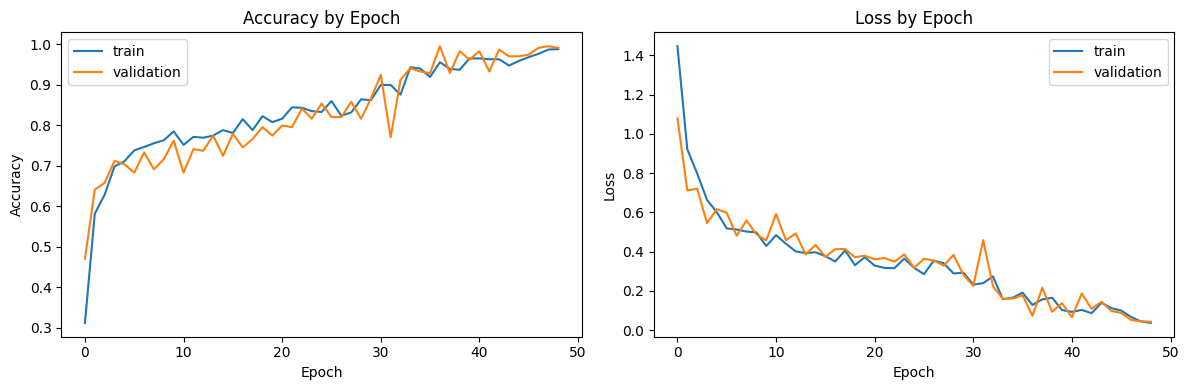

후보 모델 파일: /content/cnn_candidate_03/answer_3.h5
후보 예측 CSV: /content/cnn_candidate_03/answer_3.csv
예측 결과 크기: (300, 2)
       file_name  label
0  test_0001.png  truck
1  test_0002.png  truck
2  test_0003.png   heli
3  test_0004.png  truck
4  test_0005.png   none
검증 정확도 93% 목표: 달성


In [38]:
# 3번 답안 작성 — 한 셀에서 압축 해제부터 CNN 학습, 검증, 후보 제출 파일 생성까지
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory, load_img, img_to_array
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Input, Rescaling, RandomFlip, RandomRotation,
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# 1. 데이터 경로와 출력 경로
DATA_DIR = Path('/content')
IMG_DIR = DATA_DIR
TRAIN_DIR = IMG_DIR / '03_train'
TEST_DIR = IMG_DIR / '03_test'
CANDIDATE_DIR = DATA_DIR / 'cnn_candidate_03'
CANDIDATE_DIR.mkdir(parents=True, exist_ok=True)

# 2. 이미지 압축 해제 (한 번만)
if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    with zipfile.ZipFile(DATA_DIR / '03_images.zip') as z:
        z.extractall(IMG_DIR)

# 3. 데이터 불러오기 및 라벨 확인
train = pd.read_csv(DATA_DIR / '03_train.csv')
test = pd.read_csv(DATA_DIR / '03_test_x.csv')
print('학습 데이터:', train.shape)
print('테스트 데이터:', test.shape)
print('라벨별 개수:')
print(train['label'].value_counts())

# 4. 훈련/검증 데이터셋 생성
SIZE, MODE, BATCH = 48, 'grayscale', 32
SEED = 42
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

kw = dict(
    image_size=(SIZE, SIZE),
    batch_size=BATCH,
    validation_split=0.2,
    seed=SEED,
    color_mode=MODE
)
tr_ds = image_dataset_from_directory(str(TRAIN_DIR), subset='training', **kw)
va_ds = image_dataset_from_directory(str(TRAIN_DIR), subset='validation', **kw)
CLASSES = tr_ds.class_names
print('클래스 번호 순서:', dict(enumerate(CLASSES)))
assert len(CLASSES) == 5, f'클래스 수 이상: {CLASSES}'

# 5. CNN 구성: 흑백 1채널 → 특징 추출 → 5종 분류
cnn_model = Sequential([
    Input(shape=(SIZE, SIZE, 1)),
    Rescaling(1./255),
    RandomFlip('horizontal_and_vertical'),
    RandomRotation(0.06),

    Conv2D(32, 3, padding='same', activation='relu'),
    Conv2D(32, 3, padding='same', activation='relu'),
    MaxPooling2D(2),

    Conv2D(64, 3, padding='same', activation='relu'),
    Conv2D(64, 3, padding='same', activation='relu'),
    MaxPooling2D(2),

    Conv2D(128, 3, padding='same', activation='relu'),
    MaxPooling2D(2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(len(CLASSES), activation='softmax')
])
cnn_model.summary()

# 6. 학습 설정
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 7. 최고 검증 모델 저장 및 조기 종료
best_path = CANDIDATE_DIR / 'answer_3.h5'
callbacks = [
    ModelCheckpoint(str(best_path), monitor='val_accuracy', mode='max',
                    save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', mode='max', patience=12,
                  restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=5, min_lr=1e-5, verbose=1)
]

# 8. CNN 학습: Epoch별 accuracy, val_accuracy, loss, val_loss 출력
history = cnn_model.fit(
    tr_ds,
    validation_data=va_ds,
    epochs=60,
    callbacks=callbacks
)

# 9. 검증 정확도가 가장 높았던 모델을 파일에서 다시 불러와 평가
best_cnn = load_model(str(best_path))
valid_loss, valid_acc = best_cnn.evaluate(va_ds, verbose=0)
print(f'최고 검증 정확도: {max(history.history["val_accuracy"]):.4f}')
print(f'최종 재로드 검증 정확도: {valid_acc:.4f}')
print(f'최종 재로드 검증 손실: {valid_loss:.4f}')

# 10. 학습 과정 시각화 (GitHub 복습용)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='validation')
axes[0].set_title('Accuracy by Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='validation')
axes[1].set_title('Loss by Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
plt.tight_layout()
plt.savefig(CANDIDATE_DIR / 'learning_curves.png', dpi=150)
plt.show()

# 11. 테스트 이미지: CSV 순서대로 불러오기
images = []
for filename in test['file_name']:
    path = TEST_DIR / filename
    if not path.exists():
        raise FileNotFoundError(path)
    img = load_img(str(path), color_mode=MODE, target_size=(SIZE, SIZE))
    images.append(img_to_array(img))
images = np.stack(images).astype('float32')

# 12. 테스트 예측 및 라벨 변환
proba = best_cnn.predict(images, batch_size=BATCH, verbose=0)
indices = np.argmax(proba, axis=1)
labels = [CLASSES[int(i)] for i in indices]

# 13. CSV 제출 파일 후보 생성 (원본 파일/기존 100점 백업 유지)
answer_3 = test.copy()
answer_3['label'] = labels
answer_3.to_csv(CANDIDATE_DIR / 'answer_3.csv', index=False)

# 14. 제출 형식 확인
assert len(answer_3) == len(test) == 300
assert answer_3.columns.tolist() == test.columns.tolist() + ['label']
assert answer_3['label'].isin(CLASSES).all()
print('후보 모델 파일:', best_path)
print('후보 예측 CSV:', CANDIDATE_DIR / 'answer_3.csv')
print('예측 결과 크기:', answer_3.shape)
print(answer_3.head())
print('검증 정확도 93% 목표:', '달성' if valid_acc >= 0.93 else '미달 — 추가 실험 필요')

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

압축을 풀고 폴더 구조(학습: 클래스별 폴더, 테스트: 한 폴더)를 확인합니다. 이미지를 같은 크기로 읽어 0~1 로 맞추고, 검증 데이터를 떼어 **작은 CNN**(또는 사전학습 모델 특징 + 분류기)을 학습합니다. 증강·Dropout·조기 종료로 과적합을 막고, 테스트는 `03_test_x.csv` 순서대로 예측하세요.

- 이 문항의 핵심: 흑백 영상이므로 `color_mode='grayscale'`(채널 1)로 읽습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `tensorflow`, `pandas`, `image_dataset_from_directory`, `load_img`, `img_to_array`, `Sequential`, `load_model`, `Input`, `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`, `Dropout`, `EarlyStopping`.

- 참고 문서: <https://keras.io/api/data_loading/image/>
- 참고 문서: <https://keras.io/api/data_loading/image/#loadimg-function>
- 참고 문서: <https://keras.io/api/data_loading/image/#imgtoarray-function>
- 참고 문서: <https://keras.io/api/models/sequential/>
- 참고 문서: <https://keras.io/api/layers/convolution_layers/convolution2d/>
- 참고 문서: <https://keras.io/api/layers/pooling_layers/max_pooling2d/>

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
IMG_DIR = os.environ.get('____', '____')        # 압축을 풀 위치(브라우저판은 메모리 폴더 /tmp)
if not os.path.exists(os.path.join(IMG_DIR, '____')):
    zipfile.ZipFile('03_images.zip').extractall(IMG_DIR)
import ____
from tensorflow.keras.utils import ____, ____, ____
from tensorflow.keras.models import ____, ____
from tensorflow.keras.layers import ____, ____, ____, ____, ____, ____
from tensorflow.keras.callbacks import ____, ____, ____

test = pd.read_csv('03_test_x.csv')
SIZE, MODE = ____, '____'
kw = dict(image_size=(SIZE, SIZE), batch_size=____, validation_split=____, seed=____, color_mode=MODE)
tr_ds = image_dataset_from_directory(f'____', subset='____', **kw)
va_ds = image_dataset_from_directory(f'____', subset='____', **kw)
CLASSES = tr_ds.class_names                               # 폴더 이름(알파벳 순) = 라벨 번호 순서


# ▷ 모델 구성(CNN 또는 사전학습 특징 추출)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_3.h5`(모델) · `answer_3.csv`(예측)

</details>

## 제출할 파일 목록

| 문항 | 모델 파일 | 예측 파일 |
|---|---|---|
| 1. Tabular | answer_1.pkl (다른 확장자 가능) | answer_1.csv |
| 2. Text | answer_2.pkl (다른 확장자 가능) | answer_2.csv |
| 3. Image | answer_3.h5 (다른 확장자 가능) | answer_3.csv |
| 공통 | 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장) | |

(주의) 제출 파일명은 **고정**입니다. 위 표의 이름 그대로 저장하세요(앞부분 `answer_` · 문항 번호 · 확장자).
**예시 : answer_1.pkl , answer_1.csv** (이름을 바꾸거나 공백·대쉬(-)를 넣으면 채점되지 않습니다)

## 안내사항

- 이 모의고사는 브라우저 주피터라이트에서 미리 설치된 라이브러리만 씁니다(맨 위 '사용할 수 있는 라이브러리' 표).
- 모델 저장시 본인이 사용하는 프레임워크의 모델 저장 확장자를 사용하셔도 됩니다.(h5, keras, pkl, pickle 등)

수고하셨습니다.

In [42]:
# 전체 자동 채점 — 세 문항의 제출 파일(answer_1~3.csv·모델 파일)을 만든 뒤 이 셀을 실행하세요.
# 정답(테스트 라벨)은 압축·인코딩되어 있어 보이지 않습니다. 문항별 지표·통과 여부와 총점을 출력합니다.
PREFIX = 'answer'                                  # 제출 파일명 앞부분(고정)

import base64, json, os, re, zlib
import numpy as np
import pandas as pd

_KEY = "IoD3AJfQeW1KJE+56TOghSwEP0PWjYETliC2m6zcVpEaVHx2ljtTPhNYyWrdduO+auplk2PVOSGFeweHsDTV/nAPMyYz8X/PDmUFzxC/JIflAPXEddCRF6XxhOmNp7/wptdc56SPMOSGGD1IzDXRs6k4C+Su1eWlLuKnLubngWW21EWFrpHrkTjhxJU6Kifjc/o9ATbsyfW90VhgmTII5yVFlmyFm7KRuCBoAQ/xlwUOif2xNdA3o0RcuWLZ5/3Blz5rBVgnTt6LSmD125t2csGZ+j4zTv7ZBEiesMtcOUJCVCADylUgY+4canXfI2vKf6qSOy5S93Zyn1b7T5vm8A9ncNB2ErpLWTdS1XtWnjDPe+5ostE7BIT0yFo3AIncanUPWQsCZzuV9rxtWOAet06bnjuRNQRRSPHvcPwdb0WPFJegC+cH8IzR2EsW085I6ADKSkQ57xqMaGLwD05x7w8+E3cZDKsBt87t9pywC/P4OHvz78py7OgMWyOHQBnxO3z0l8hxdInA7EgiLvD35kzpwG0M9XN29aySjpBz6suN9demEAOT81cRxHU0XGfftqJL6OkJPrVlhkWlIuWl6qGouf2d6sSUPPWMiYPvU7cCWLcSGSxC1vgrWbakq83F1SW32rwiJS0ioQGHgLelJxoBLa2dLbXwjFP3P+63oaixNKWqmSWltmWlIyLxtY+XNQG/irukJxMl4qeBrIQLQXlsM4BkyVXZ5L+bnGnzUdGsro93MYiANR0XVy7mLi78FENIEe45gZE8kxRw0S9z8xbB03aOtzEZ/I3ANEEAonoLOzHjStUpNonxXr1H3e5G/EzfBJKf0085wsSqwpv4PJ9SaEgCSx0jaO9JR2sX1X1n2k2TKsVK+tMeVBEoUBt243eySCsTHWyI7Gau0aYdTuliqw7cbxDlfsCy4j3LxhhqT+mWUpBm9RO1aXfVAdxgyz8EltA7PpR/qH3of9YkRl5pbhwj/KI+7iN3cXCouFn7Awy8sUF3KmBUMMTAowAqMqkgWJO+0xO9N2jBK+bC0Fj+3t4G7NYWwsEJhmrph+nH4cjjyMmMZ83rwLLEGvkRzH9KS9HfczxUOJ/It5w9s/kLmx9zfeDKPcM3LYzTFDwk6KHsscfNkSooCfuXPy1GAHmMC2h5ebWclvBXuSbNHDG14Wq57r6qeNTqHkyx1DCoYrKS9EfMnJQYFZfKRLMtVfsxLdSW2S3tuqu7wyOiuMfPB+rnmUtfYuPA4my+L8Hpg4crYKOE8SIxkrRkpsF7kRg9uZHtKL598Zc4xmBox2/RcEnoIH5pEBC5U8fHkzF8yBDedljFacEvP/bmYPKyLDzpT8eHyE+AKYdkpmfIKVCScK7m1oeV7bPAwPKsEJ0loEVevKVmLm/bqcXQdl0hEBStriYOxm1hpCe7jep+LTLl0HW9LHVgLUbvJxNct8NlowzeHm0pYNighsE+6wYu8bulpRWl2ZLzZmpwR2RPDUU2oqUZKNQB1QUccqEk2Q17PLOqvsHAXqX8/DRqZfwTqtUzOpQ+Y+d2rjUwSKnBwD6CJAnpB+XA5/YSwJztnzik8jnjAPAfzYDej7AwKWD5o289bmei0pNS7PUT+xeKg5okQWApsTT+O+m3G8KbX2Y376FCkYD8MQGAvEBsadwud7iYODDp69fp+vX4OZm6WZ/B03zHmFMSQZauY6AwfPn8p0rXS+DsM9T7F0Accp3S+Bbv+owrOVTvzVeH3kQq/FLLC0sTRRmujLf9odbrXET3dkGxEH8K01rQUBJ0asDuOJWp73598rvLkG7zWiFc1zsGFO6a+OYdNvpa2F1qLdKJ93DaVLsF4GRrwRIYdOxMkZR0FSs9czJ+mT4f1W54Mxuv2f58Hl78eFHIquJrHX5SwA5NbU1tpVlkkHiW"


def _key():
    raw = base64.b64decode(_KEY)
    return json.loads(zlib.decompress(bytes(b ^ 0x5A for b in raw)).decode("utf-8"))


def _metric(m, y, p):
    if m == "rmse":
        return float(np.sqrt(np.mean((np.asarray(p, float) - np.asarray(y, float)) ** 2)))
    y, p = np.asarray(y).astype(str), np.asarray(p).astype(str)
    if m == "accuracy":
        return float((y == p).mean())
    labels = sorted(set(y)) if m == "macro_f1" else ["1"]
    f1s = []
    for c in labels:
        tp = np.sum((p == c) & (y == c)); fp = np.sum((p == c) & (y != c)); fn = np.sum((p != c) & (y == c))
        f1s.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f1s))


def grade(prefix="answer", folder="."):
    key = _key()
    phone = prefix                                      # 제출 파일명 앞부분(고정: answer_N.csv · answer_N.pkl/.h5)
    total, rows = 0, []
    for q in key["problems"]:
        no, pts = q["no"], q["points"]
        csv = os.path.join(folder, f"{phone}_{no}.csv")
        models = [f for f in os.listdir(folder) if f.startswith(f"{phone}_{no}.") and not f.endswith(".csv")]
        msg, score, val = [], 0, None
        if not models:
            msg.append("모델 파일 없음")
        if not os.path.exists(csv):
            rows.append((no, pts, 0, None, "예측 CSV 없음")); continue
        sub = pd.read_csv(csv)
        test = pd.read_csv(os.path.join(folder, q["test_file"]))
        lab = q["label"]
        if list(sub.columns) != list(test.columns) + [lab]:
            msg.append(f"열 구조가 다름(테스트 열 + 마지막 '{lab}' 열이어야 함)")
        if lab not in sub.columns or len(sub) != len(test):
            rows.append((no, pts, 0, None, f"행 수 {len(sub)} ≠ {len(test)} 또는 '{lab}' 열 없음")); continue
        keycol = q["key_col"]
        if keycol and not (sub[keycol].astype(str).values == test[keycol].astype(str).values).all():
            msg.append(f"'{keycol}' 순서가 테스트 파일과 다름")
        if sub[lab].isna().any():
            msg.append("예측값에 결측 있음"); sub[lab] = sub[lab].fillna(0 if q["metric"] == "rmse" else "")
        val = _metric(q["metric"], q["y"], sub[lab].values)
        ok = val <= q["pass_line"] if q["metric"] == "rmse" else val >= q["pass_line"]
        if ok and not msg:
            score = pts
        rows.append((no, pts, score, val, "; ".join(msg) or ("통과" if ok else "기준선 미달")))
        total += score
    print(f"{'문항':<6}{'배점':>4}{'점수':>6}  {'지표':<10}{'결과':>10}  {'목표':>8}  {'기준선':>8}  비고")
    for (no, pts, sc, val, note), q in zip(rows, key["problems"]):
        v = "-" if val is None else (f"{val:.4f}")
        print(f"{no:<6}{pts:>4}{sc:>6}  {q['metric']:<10}{v:>10}  {q['target']:>8}  {q['pass_line']:>8}  {note}")
    print(f"총점: {total} / 100  ({'합격' if total >= 80 else '불합격'}, 합격 기준 80점)")
    return total


_점수 = grade(prefix=PREFIX)

문항      배점    점수  지표                결과        목표       기준선  비고
1       30    30  rmse          0.8816     0.925    1.0175  통과
2       35    35  accuracy      0.9694      0.91     0.819  통과
3       35    35  accuracy      0.9733      0.93     0.837  통과
총점: 100 / 100  (합격, 합격 기준 80점)
